*****Partie 1 : Introduction au Dataset*****

**Téléchargement de  dataset**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.preprocessing import StandardScaler


path = os.path.expanduser("~/Desktop/master/aprentissage/titanic.xls")



df = pd.read_excel(path)


***Les demention de dataset***

In [174]:
print(df.shape)

(1309, 14)


***Identifiez les types de données (numériques, catégorielles).***

In [175]:
#   les donnes  numériques
num_col = df.select_dtypes(include=['int64', 'float64']).columns

#   les donnes catégorielles
cat_col = df.select_dtypes(include=['object', 'category']).columns

print("les Colonnes numériques :")
print(num_col)

print("\n les Colonnes catégorielles :")
print(cat_col)

les Colonnes numériques :
Index(['pclass', 'survived', 'age', 'sibsp', 'parch', 'fare', 'body'], dtype='object')

 les Colonnes catégorielles :
Index(['name', 'sex', 'ticket', 'cabin', 'embarked', 'boat', 'home.dest'], dtype='object')


***Visualisez les premières lignes du dataset.***

In [176]:
print ( df.head () ) # premieres lignes


   pclass  survived                                             name     sex  \
0       1         1                    Allen, Miss. Elisabeth Walton  female   
1       1         1                   Allison, Master. Hudson Trevor    male   
2       1         0                     Allison, Miss. Helen Loraine  female   
3       1         0             Allison, Mr. Hudson Joshua Creighton    male   
4       1         0  Allison, Mrs. Hudson J C (Bessie Waldo Daniels)  female   

       age  sibsp  parch  ticket      fare    cabin embarked boat   body  \
0  29.0000      0      0   24160  211.3375       B5        S    2    NaN   
1   0.9167      1      2  113781  151.5500  C22 C26        S   11    NaN   
2   2.0000      1      2  113781  151.5500  C22 C26        S  NaN    NaN   
3  30.0000      1      2  113781  151.5500  C22 C26        S  NaN  135.0   
4  25.0000      1      2  113781  151.5500  C22 C26        S  NaN    NaN   

                         home.dest  
0                     St 

***Vérifiez les valeurs manquantes avec df.isnull().sum().***

In [177]:
print ( df.isnull ().sum () )

pclass          0
survived        0
name            0
sex             0
age           263
sibsp           0
parch           0
ticket          0
fare            1
cabin        1014
embarked        2
boat          823
body         1188
home.dest     564
dtype: int64


***Partie 2 : Nettoyage des Données***

**1. Gestion des valeurs manquantes**

**Identifiez les colonnes avec des valeurs manquantes.**

**voir reponse dans le raport**

***Appliquez une des stratégies suivantes pour gérer les valeurs manquantes :***

***Pour les variables numériques, remplacez les valeurs manquantes par
la moyenne ou la médiane.***

In [195]:
df = pd.read_excel(path)

# Vérifier les valeurs manquantes avant traitement
print("avant:", df["age"].isnull().sum())

# Sauvegarder les âges originaux
age_avant = df["age"].copy()

# Calculer la médiane
mediane = df["age"].median()

# Remplacer les valeurs manquantes par la médiane
df["age"] = df["age"].fillna(mediane)

# Vérifier après traitement
print("apres :", df["age"].isnull().sum())
print("mediane utilise :", mediane)

avant: 263
apres : 0
mediane utilise : 28.0


***Pour les variables catégorielles, remplacez les valeurs manquantes par
la mode (valeur la plus fréquente).***

In [182]:
# Identifier les variables catégorielles
cat_cols = df.select_dtypes(include=['object']).columns

# Remplacer les valeurs manquantes par le mode
for col in cat_cols:
    df[col].fillna(df[col].mode()[0], inplace=True)

# verification des resultat
print(df[cat_cols].isnull().sum())

name         0
sex          0
ticket       0
cabin        0
embarked     0
boat         0
home.dest    0
dtype: int64


/tmp/ipykernel_10489/4239742478.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].mode()[0], inplace=True)


***Si une variable possède trop de valeurs manquantes (plus de 40 %), vous
pouvez envisager de la supprimer.***

**en afiche la porsentage des colonnes**

In [183]:
pct = df . isnull () . mean () * 100
print ( pct [ pct > 0]. sort_values ( ascending = False ) )

body    90.756303
age     20.091673
fare     0.076394
dtype: float64


In [184]:

 missing_percent = df.isnull().mean() * 100

cols_to_drop = missing_percent[missing_percent > 40].index

df.drop(columns=cols_to_drop, inplace=True)

print("les Colonnes  a supprimées est  :", list(cols_to_drop))

les Colonnes  a supprimées est  : ['body']


***2. Gestion des valeurs aberrantes :***

**Utilisez des boxplots pour détecter des valeurs aberrantes dans les variables
numériques.**

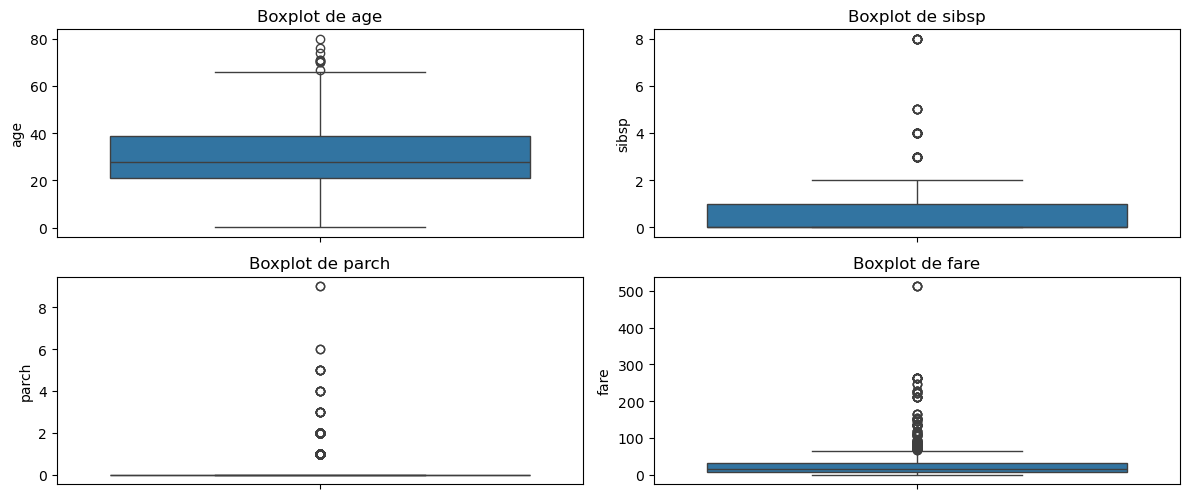

In [185]:
import matplotlib.pyplot as plt
import seaborn as sns

num_cols = ['age', 'sibsp', 'parch', 'fare']

plt.figure(figsize=(12, 10))

for i, col in enumerate(num_cols):
    plt.subplot(4, 2, i + 1)
    sns.boxplot(y=df[col])
    plt.title(f'Boxplot de {col}')

plt.tight_layout()
plt.show()

In [186]:
num_cols = ['age', 'sibsp', 'parch', 'fare', ]

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"\nVariable : {col}")
    print(f"Nombre de valeurs aberrantes : {len(outliers)}")
    print(outliers[[col]].head(10))


Variable : age
Nombre de valeurs aberrantes : 9
       age
9     71.0
14    80.0
61    76.0
81    70.0
135   71.0
285   67.0
506   70.0
727   70.5
1235  74.0

Variable : sibsp
Nombre de valeurs aberrantes : 57
     sibsp
111      3
112      3
113      3
114      3
545      3
622      4
623      4
624      4
625      4
626      4

Variable : parch
Nombre de valeurs aberrantes : 307
    parch
1       2
2       2
3       2
4       2
16      1
17      1
20      1
21      1
36      1
49      1

Variable : fare
Nombre de valeurs aberrantes : 171
        fare
0   211.3375
1   151.5500
2   151.5500
3   151.5500
4   151.5500
6    77.9583
10  227.5250
11  227.5250
12   69.3000
13   78.8500


*Après avoir examiné les valeurs aberrantes détectées, j'ai choisi
de ne pas les remplacer par la médiane et de ne pas supprimer les lignes correspondantes. 
En effet, ces valeurs représentent des observations réelles et restent cohérentes avec la réalité. 
Même si elles sont considérées comme des valeurs aberrantes par la méthode IQR, elles
ne constituent pas nécessairement des erreurs. J'ai donc préféré les conserver afin de préserver les informations du dataset.*

***. Appliquer des transformations sur les données (normalisation et standardisation).***

**1. Normalisation**

In [187]:
from sklearn.preprocessing import MinMaxScaler

num_cols = ['age', 'sibsp', 'parch', 'fare']

scaler = MinMaxScaler()

df_nz = df.copy()

df_nz[num_cols] = scaler.fit_transform(df[num_cols])

df_nz[num_cols].head()

,age,sibsp,parch,fare
0,0.361169,0.000,0.000000,0.412503
1,0.009395,0.125,0.222222,0.295806
2,0.022964,0.125,0.222222,0.295806
3,0.373695,0.125,0.222222,0.295806
4,0.311064,0.125,0.222222,0.295806


**Après la normalisation, les valeurs des variables **age**, **sibsp**, **parch** et **fare** sont comprises entre 0 et 1. Cette transformation permet de mettre les variables sur la même échelle, tout en conservant leurs différences relatives. Elle facilite ainsi leur utilisation dans les modèles de Machine Learning.**

**2. Standardisation**

In [188]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

df_st = df.copy()

df_st[num_cols] = scaler.fit_transform(df[num_cols])

df_st [num_cols].head()

,age,sibsp,parch,fare
0,-0.061162,-0.479087,-0.445000,3.441165
1,-2.010496,0.481288,1.866526,2.285603
2,-1.935302,0.481288,1.866526,2.285603
3,0.008251,0.481288,1.866526,2.285603
4,-0.338812,0.481288,1.866526,2.285603


**Après la standardisation, les valeurs des variables **age**, **sibsp**, **parch** et **fare** sont transformées autour d'une moyenne proche de 0 et d'un écart-type proche de 1. Les valeurs positives indiquent des valeurs supérieures à la moyenne, tandis que les valeurs négatives indiquent des valeurs inférieures à la moyenne. Cette transformation permet de mettre les variables sur une échelle comparable pour faciliter leur utilisation dans les modèles de Machine Learning.**

***comparaison entre les donnees originales et les donnees normalisees et standardisees***

In [189]:
print("Données originales :")
display(df[num_cols].head())

print("Données normalisées :")
display(df_nz[num_cols].head())

print("Données standardisées :")
display(df_st[num_cols].head())

Données originales :


,age,sibsp,parch,fare
0,29.0000,0,0,211.3375
1,0.9167,1,2,151.5500
2,2.0000,1,2,151.5500
3,30.0000,1,2,151.5500
4,25.0000,1,2,151.5500


Données normalisées :


,age,sibsp,parch,fare
0,0.361169,0.000,0.000000,0.412503
1,0.009395,0.125,0.222222,0.295806
2,0.022964,0.125,0.222222,0.295806
3,0.373695,0.125,0.222222,0.295806
4,0.311064,0.125,0.222222,0.295806


Données standardisées :


,age,sibsp,parch,fare
0,-0.061162,-0.479087,-0.445000,3.441165
1,-2.010496,0.481288,1.866526,2.285603
2,-1.935302,0.481288,1.866526,2.285603
3,0.008251,0.481288,1.866526,2.285603
4,-0.338812,0.481288,1.866526,2.285603


***3. Traiter les données déséquilibrées dans un dataset.***

Dans cette étape, nous avons étudié la répartition des classes de la variable cible survived afin de vérifier si le dataset Titanic est équilibré ou déséquilibré.

La variable survived contient deux classes :

0 : passagers qui n'ont pas survécu.

1 : passagers qui ont survécu.

Pour vérifier la répartition des classes, nous avons utilisé la fonction value_counts() afin de compter les observations de chaque classe, puis nous avons calculé leurs pourcentages.

In [190]:
# Compter les observations de chaque classe
print(df['survived'].value_counts())

# Afficher les proportions en pourcentage
print(df['survived'].value_counts(normalize=True) * 100)

survived
0    809
1    500
Name: count, dtype: int64
survived
0    61.802903
1    38.197097
Name: proportion, dtype: float64


**1 separation de dataset**

In [191]:
from sklearn.model_selection import train_test_split

X = df.drop('survived', axis=1)
y = df['survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

**2. Appliquer Random Oversampling**

In [192]:
from imblearn.over_sampling import RandomOverSampler

ros = RandomOverSampler(random_state=42)

X_train_random, y_train_random = ros.fit_resample(
    X_train, y_train
)

print("Après Random Oversampling :")
print(y_train_random.value_counts())

Après Random Oversampling :
survived
1    647
0    647
Name: count, dtype: int64


**3. Appliquer SMOTE**

In [194]:
from imblearn.over_sampling import SMOTE
from sklearn.impute import SimpleImputer

# Garder uniquement les variables numériques
X_train_num = X_train.select_dtypes(include=['number'])

# Remplacer les valeurs manquantes
imputer = SimpleImputer(strategy='median')
X_train_num = imputer.fit_transform(X_train_num)

# Appliquer SMOTE
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_num, y_train
)

print("Après SMOTE :")
print(y_train_smote.value_counts())

Après SMOTE :
survived
1    647
0    647
Name: count, dtype: int64
